Code & executed notebook:


# 777 Radio — First Pipeline
### Can a model learn how *I* tag songs, just by listening to them?

I built [777 Radio](https://777radio.vercel.app/), an app where you upload an image and it plays songs that match its vibe.
Behind the scenes, every song in the library has tags that I wrote by hand: moods, scenes, colors, places, random
associations ("girlypop, Y2K, pink, nightclub", "night walk, rain, city lights"...). The app describes the image and then
matches it against my tags.

The problem: tagging every single new song by hand is slow, and it is the main thing stopping me from growing the library.
So the question for this pipeline is:

> **Given a song the model has never heard, can it predict the tags I would give it, using only the audio?**

I ended up testing this in two ways, because my tags turned out to be much messier than I expected (more on that in Section 3):

| | Part A: broad labels | Part B: my exact tags |
|---|---|---|
| **What is predicted** | 3 broad labels I built from my tags: *energetic, melancholic, romantic* | The 10 tags (out of 600+) I would most likely write for a song |
| **Models** | 2 baselines, logistic regression, decision tree, SVM | Popularity baseline, kNN, kNN + popularity prior, CLAP zero-shot |
| **Features** | Handcrafted `librosa` features (33-d) vs. CLAP embeddings (512-d) | Same two |
| **Evaluation** | Precision / recall / F1, 5-fold CV + held-out test | Precision@10, Recall@10, soft precision, tag variety |

Both parts use the **same 115 / 30 train–test split**.

*To run:* the Drive project folder needs `music-dataset.csv` and `777 radio.zip`. Audio features and CLAP embeddings are
cached in `outputs/`, so after the first run nothing slow is recomputed.

## 1. Setup

In [1]:
%pip -q install librosa soundfile transformers sentence-transformers

In [2]:
import os, re, json, shutil, zipfile, unicodedata, warnings
from pathlib import Path
from collections import Counter
from difflib import SequenceMatcher

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_val_score)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*ill-defined.*")   # F1 of the majority baseline is 0 by design
pd.set_option("display.max_colwidth", 120)

SEED = 42            # one seed for every split / model, so results are reproducible
N_TEST = 30          # hold out 30 songs for testing while keeping 115 for training
K = 10               # number of tags recommended per song in Part B
np.random.seed(SEED)

In [3]:
# Mount Google Drive when running in Colab
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Project folder: first candidate that contains the song CSV
candidates = [Path(os.environ.get("PROJECT_DIR", "")),
              Path("/content/drive/MyDrive/777_radio_project (1)"),
              Path("/content/drive/MyDrive/777_radio_project")]
PROJECT = next(p for p in candidates if str(p) not in ("", ".") and (p / "music-dataset.csv").exists())

OUT = PROJECT / "outputs"
FIG = PROJECT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
AUDIO_DIR = Path("/content/777_radio_audio") if IN_COLAB else PROJECT / "audio_tmp"

print("Project folder:", PROJECT)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/777_radio_project


### Pipeline at a glance

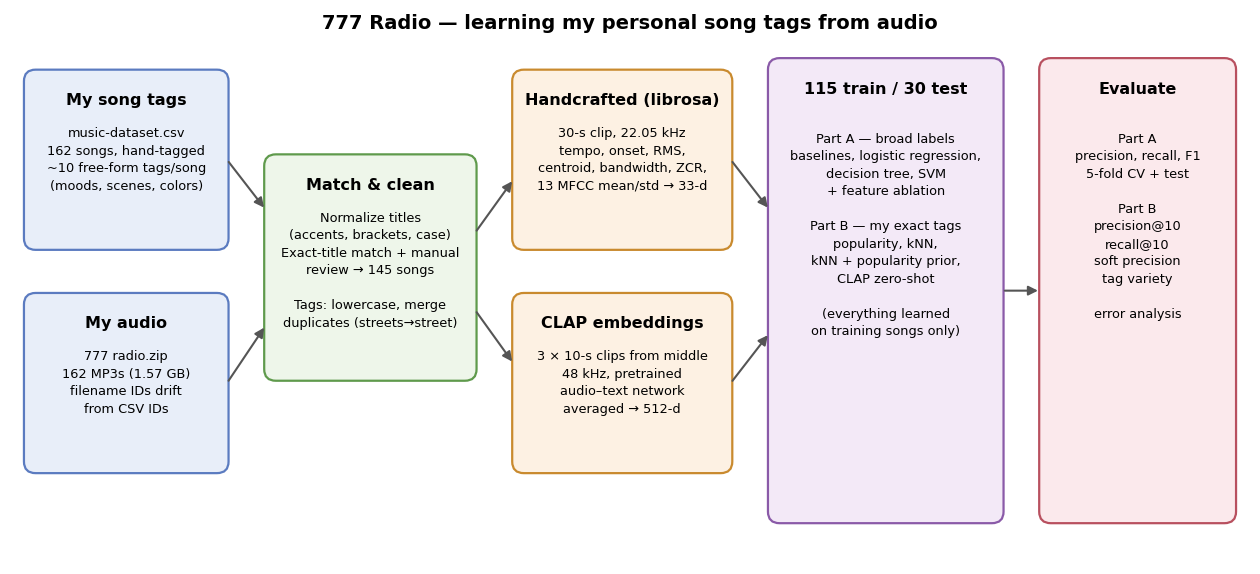

In [4]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(16, 7.2))
ax.set_xlim(0, 16); ax.set_ylim(0, 7.2); ax.axis("off")
FILL = {"data": "#e8eef9", "pre": "#eef6ea", "feat": "#fdf1e3", "model": "#f3e9f7", "eval": "#fbe9ec"}
EDGE = {"data": "#5b7bc0", "pre": "#5f9a4c", "feat": "#c98a2e", "model": "#8a5aa8", "eval": "#b8505f"}

def box(x, y, w, h, kind, title, body):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                fc=FILL[kind], ec=EDGE[kind], lw=1.6))
    ax.text(x + w / 2, y + h - 0.28, title, ha="center", va="top", fontsize=11.5, weight="bold")
    ax.text(x + w / 2, y + h - 0.72, body, ha="center", va="top", fontsize=9.3, linespacing=1.45)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.5, mutation_scale=14))

ax.text(8, 6.95, "777 Radio — learning my personal song tags from audio", ha="center", fontsize=14, weight="bold")
box(0.2, 4.1, 2.6, 2.3, "data", "My song tags", "music-dataset.csv\n162 songs, hand-tagged\n~10 free-form tags/song\n(moods, scenes, colors)")
box(0.2, 1.2, 2.6, 2.3, "data", "My audio", "777 radio.zip\n162 MP3s (1.57 GB)\nfilename IDs drift\nfrom CSV IDs")
box(3.3, 2.4, 2.7, 2.9, "pre", "Match & clean", "Normalize titles\n(accents, brackets, case)\nExact-title match + manual\nreview → 145 songs\n\nTags: lowercase, merge\nduplicates (streets→street)")
arrow(2.8, 5.25, 3.3, 4.6); arrow(2.8, 2.35, 3.3, 3.1)
box(6.5, 4.1, 2.8, 2.3, "feat", "Handcrafted (librosa)", "30-s clip, 22.05 kHz\ntempo, onset, RMS,\ncentroid, bandwidth, ZCR,\n13 MFCC mean/std → 33-d")
box(6.5, 1.2, 2.8, 2.3, "feat", "CLAP embeddings", "3 × 10-s clips from middle\n48 kHz, pretrained\naudio–text network\naveraged → 512-d")
arrow(6.0, 4.3, 6.5, 5.0); arrow(6.0, 3.3, 6.5, 2.6)
box(9.8, 0.55, 3.0, 6.0, "model", "115 train / 30 test",
    "\nPart A — broad labels\nbaselines, logistic regression,\ndecision tree, SVM\n+ feature ablation\n\nPart B — my exact tags\npopularity, kNN,\nkNN + popularity prior,\nCLAP zero-shot\n\n(everything learned\non training songs only)")
arrow(9.3, 5.25, 9.8, 4.6); arrow(9.3, 2.35, 9.8, 3.0)
box(13.3, 0.55, 2.5, 6.0, "eval", "Evaluate",
    "\nPart A\nprecision, recall, F1\n5-fold CV + test\n\nPart B\nprecision@10\nrecall@10\nsoft precision\ntag variety\n\nerror analysis")
arrow(12.8, 3.55, 13.3, 3.55)
plt.savefig(FIG / "pipeline_diagram.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## 2. The data: my hand-tagged songs + their MP3s

**The tags.** `music-dataset.csv` is literally the database behind 777 Radio: 162 songs, each with the free-form tags I
wrote while building the app. There is no fixed category list; I just wrote whatever the song made me picture.

**The audio.** 777 radio.zip has 162 MP3s (1.57 GB) of the songs in my Spotify playlist, which I downloaded with a third-party tool for this analysis (see Ethical considerations). They are not in the public repo because of copyright.

The first annoying surprise: each MP3 filename starts with a number that was supposed to equal `song_id`... but it
**drifts**. For example, CSV song 45 is *How Soon Is Now?*, but its file is `44. How Soon Is Now_ - Single Edit; 2008 Remaster.mp3`.
My first attempt matched files by number, which would have silently given songs the *wrong* tags. That's the worst kind of
bug, because the model would still train fine on garbage labels. So I switched to matching by title.

In [5]:
df = pd.read_csv(PROJECT / "music-dataset.csv")
print("Songs in CSV:", len(df), "| columns:", df.columns.tolist())
df.head()

Songs in CSV: 162 | columns: ['song_id', 'title', 'artist', 'context_tags', 'spotify_id']


,song_id,title,artist,context_tags,spotify_id
0,1,Girl Like Me,PinkPantheress,"girlypop, energetic, dance, funky, funny, Y2K, pink, purple, red, cute dresses, UK vibe, night, day, party, street d...",NaN
1,2,Televised,HUNNY,"good life, smile, friends, hike, nature, park, streets, daytime, morning, warmth, sun, fresh, yellow, orange, green,...",NaN
2,3,Mis Horas,Los Abuelos de la Nada,"cool, old, vintage, retro, Spanish, Argentina, wood, street, goofy, macho, laid back, relaxed, upbeat, nostalgic, ci...",NaN
3,4,Children,Robert Miles,"2000s, rich kids vibe, mansion, villa, NYC, Manhattan apartment, cars, iPhone 4, cash, money, old money, parties, cl...",NaN
4,5,4 Minutes,"Madonna, Justin Timberlake, Timbaland","dance, active, workout, run, sexy, sweaty, action, moving, cool, Y2K, 2000s, classy, fashionable, colorful, fast, ac...",NaN


In [6]:
ZIP_PATH = next(PROJECT.glob("**/777 radio.zip"), None)

if ZIP_PATH is not None:
    with zipfile.ZipFile(ZIP_PATH) as z:
        audio_files = [n for n in z.namelist()
                       if n.lower().endswith((".mp3", ".flac", ".wav", ".m4a"))
                       and not n.startswith("__MACOSX/")]
    print(f"ZIP: {ZIP_PATH.name} ({ZIP_PATH.stat().st_size / 1e9:.2f} GB) | audio files: {len(audio_files)}")
else:
    audio_files = None
    print("ZIP not found; will load the cached matching table from outputs/matched_songs.csv")

ZIP: 777 radio.zip (1.57 GB) | audio files: 162


### 2.1 Matching MP3 files to CSV rows

What the matching does:

1. Clean both titles: remove the number prefix, accents, anything in brackets like *(feat. Moby)*, punctuation and capital letters.
2. Only accept a match when the cleaned title is **unique on both sides**. That gives 142 safe matches.
3. Add 3 matches I checked by hand: a typo in my CSV (*Mis Horas* → *Mil Horas*), a Cyrillic filename (*Случайная*) and the drifted *How Soon Is Now?*.
4. Leave the other 17 songs out instead of guessing.

So **162 → 145 songs**. I decided that losing 17 songs is better than training on wrong labels. Most of the 17 are
"Single Version / Remastered / Radio Edit" suffixes or translated titles. (Also, a small bug I found later:
`Path(title).stem` treats a `.` inside a title as a file extension, so titles like *Gymnopédie No. 1* get cut.
Fixing it would add songs back, but it would also change the dataset after I'd already run the experiments, so I left it
and documented it here.)

In [7]:
def normalize_song_title(text):
    text = Path(str(text)).stem
    text = re.sub(r"^\d+\.\s*", "", text)                       # numeric file prefix
    text = unicodedata.normalize("NFKD", text).casefold()
    text = "".join(c for c in text if not unicodedata.combining(c))  # accents
    text = re.sub(r"\([^)]*\)", "", text)                         # (feat. ...)
    text = re.sub(r"\[[^]]*\]", "", text)
    text = re.sub(r"[^a-z0-9]+", " ", text)
    return " ".join(text.split())

# Hand-verified matches that title normalization cannot find
MANUAL_MATCHES = {
    3:  "3. Mil Horas.mp3",                                       # CSV typo "Mis Horas"
    28: "28. Случайная.mp3",                                      # Cyrillic title
    45: "44. How Soon Is Now_ - Single Edit; 2008 Remaster.mp3",  # ID drift
}

if audio_files is not None:
    audio_index = pd.DataFrame({"audio_filename": audio_files})
    audio_index["title_key"] = audio_index["audio_filename"].apply(normalize_song_title)
    songs = df.copy()
    songs["title_key"] = songs["title"].apply(normalize_song_title)

    # Only accept titles that are unique on both sides
    unique_csv = songs[songs["title_key"].map(songs["title_key"].value_counts()) == 1]
    unique_audio = audio_index[audio_index["title_key"].map(audio_index["title_key"].value_counts()) == 1]
    exact = unique_csv.merge(unique_audio, on="title_key", validate="one_to_one")
    final_matches = exact[["song_id", "audio_filename"]].copy()
    print("Exact title matches:", len(final_matches))

    for sid, fname in MANUAL_MATCHES.items():
        if fname in set(audio_files) and sid not in set(final_matches.song_id) \
                and fname not in set(final_matches.audio_filename):
            final_matches.loc[len(final_matches)] = [sid, fname]
    print("After manual matches:", len(final_matches))

    training_data = df.merge(final_matches, on="song_id", how="inner", validate="one_to_one")
    training_data.to_csv(OUT / "matched_songs.csv", index=False)
else:
    training_data = pd.read_csv(OUT / "matched_songs.csv")

assert training_data["song_id"].is_unique and training_data["audio_filename"].is_unique
print("Songs used in this project:", len(training_data))

Exact title matches: 142
After manual matches: 145
Songs used in this project: 145


In [8]:
# Transparency: the songs left out, with the closest remaining filename
excluded = df[~df.song_id.isin(training_data.song_id)][["song_id", "title", "artist"]].copy()
if audio_files is not None:
    left = [f for f in audio_files if f not in set(training_data.audio_filename)]
    excluded["closest_unused_file"] = excluded["title"].apply(
        lambda t: max(left, key=lambda f: SequenceMatcher(None, normalize_song_title(t), normalize_song_title(f)).ratio()))
print(f"Excluded songs: {len(excluded)}")
excluded

Excluded songs: 17


,song_id,title,artist,closest_unused_file
18,19,Smooth Operator,Sade,19. Smooth Operator - Single Version.mp3
19,20,19-2000 (Soulchild Remix),Gorillaz,20. 19-2000 - Soulchild Remix.mp3
24,25,Bizarre Love Triangle,New Order,25. Bizarre Love Triangle - Single Remix.mp3
44,46,Hit 'Em Up,2Pac,45. Hit 'Em Up - Single Version.mp3
46,48,A New Kind Of Love,"Frou Frou (Imogen Heap, Guy Sigsworth)",47. A New Kind Of Love - Demo.mp3
53,55,Beep Boop,Meaningful Stone,"54. Beep-Boop, Beep-Boop.mp3"
88,90,Alors On Danse,Stromae,89. Alors on danse - Radio Edit.mp3
94,96,Boy's a Liar Pt. 2,"PinkPantheress, Ice Spice",95. Boy's a liar Pt. 2.mp3
103,105,Spokoinaya Noch',Kino,111. Starry Night - Edit.mp3
110,112,Starry Night,Peggy Gou,111. Starry Night - Edit.mp3


## 3. My tag vocabulary (aka why this is hard)

Distinct tags: 763 | avg tags per song: 10.2
Tags used once: 527 (69%) | used >= 10 times: 16
Top 15: cool (24), streets (22), night (16), nature (15), sad (15), pink (14), love (14), cinematic (14), confident (13), cars (12), nostalgic (11), moving (11), aesthetic (11), romantic (11), purple (10)


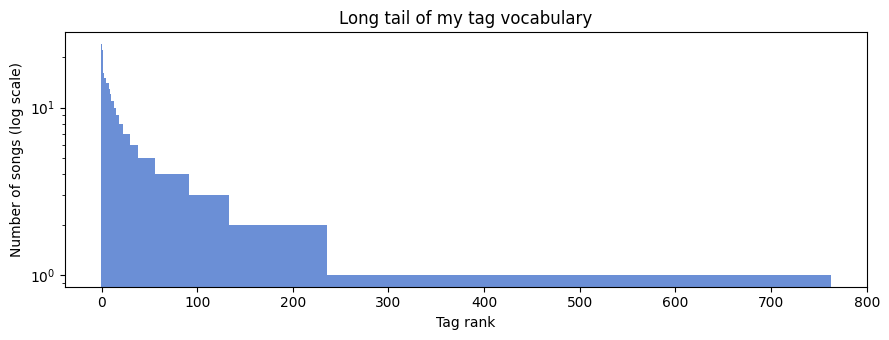

In [9]:
def split_tags(s):
    return [t.strip().lower() for t in str(s).split(",") if t.strip()]

training_data["tag_list"] = training_data["context_tags"].fillna("").apply(split_tags)
tag_counts = Counter(t for tags in training_data["tag_list"] for t in set(tags))
freq = np.array(sorted(tag_counts.values(), reverse=True))

print(f"Distinct tags: {len(tag_counts)} | avg tags per song: {training_data.tag_list.str.len().mean():.1f}")
print(f"Tags used once: {(freq == 1).sum()} ({(freq == 1).mean():.0%}) | used >= 10 times: {(freq >= 10).sum()}")
print("Top 15:", ", ".join(f"{t} ({n})" for t, n in tag_counts.most_common(15)))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(len(freq)), freq, width=1.0, color="#6b8fd6")
ax.set_yscale("log")
ax.set_xlabel("Tag rank"); ax.set_ylabel("Number of songs (log scale)")
ax.set_title("Long tail of my tag vocabulary")
plt.tight_layout(); plt.savefig(FIG / "tag_long_tail.png", dpi=150); plt.show()

This plot explains basically everything that happens later. Out of 763 distinct tags across the 145 songs, **527 (69%)
are used exactly once** ("rich kids vibe", "like Old Spice", "croissants") and only 16 are used 10+ times. The most
common ones (*cool, streets, night, sad, pink*) are kind of my "house style" and appear across totally different songs.

Two consequences:
* A model **can't learn a tag it only saw once**, so most of my vocabulary is unlearnable from other songs.
* Lots of my tags describe *images and scenes* (because 777 Radio matches images), not sound. "Croissants" is not something
  you can hear.

That's why I split the project into Part A (group tags into a few broad, learnable labels) and Part B (go for the exact tags anyway and see how far we get).

## 4. Turning songs into numbers: two audio representations

Each song $i$ becomes a feature vector $\mathbf{x}_i \in \mathbb{R}^d$, i.e. one row of numbers that describes how it sounds.
I compare two very different ways of building that vector:

**1. Handcrafted features ($d = 33$)** with `librosa`, from a 30-second clip at a reproducible random position in the song
(I first used the first 30 seconds, but intros are often quiet or spoken and don't represent the song):

* **tempo** (beats per minute) and **onset strength** (how "punchy"/rhythmic note attacks are)
* **RMS energy** mean and std: loudness and how much it changes. For a frame of samples $s_1,\dots,s_N$: $\text{RMS}=\sqrt{\tfrac{1}{N}\sum_n s_n^2}$
* **spectral centroid** (the "center of mass" of the frequencies, which is roughly how *bright* the song sounds) and **spectral bandwidth** (how spread out the frequencies are)
* **zero-crossing rate** (how often the waveform crosses zero, which is high for noisy/percussive sounds)
* **13 MFCCs (mean and std of each):** MFCC stands for Mel-Frequency Cepstral Coefficient. These features compress information about the sound's frequency characteristics and help represent timbre, or sound texture. For example, a piano and a distorted guitar can have the same pitch but sound very different.

**2. CLAP embeddings ($d = 512$).** CLAP is a **pretrained neural network** (`laion/clap-htsat-unfused`) that I only use to
turn audio into vectors. **I did not train it.** It was trained by its authors on huge numbers of (audio, text caption)
pairs with a contrastive loss:
$$\mathcal{L}=-\frac{1}{N}\sum_{i=1}^{N}\log\frac{\exp(\mathbf{a}_i\cdot\mathbf{t}_i/\tau)}{\sum_{j=1}^{N}\exp(\mathbf{a}_i\cdot\mathbf{t}_j/\tau)}$$
Here $\mathbf{a}_i$ is the embedding of audio clip $i$, $\mathbf{t}_i$ the embedding of its matching caption, and $\tau$ a
temperature. The loss is small when each clip is closer to *its own* caption than to all the other captions in the batch.
The result is that audio and text live in the same 512-d space, which I use twice: as richer features (Parts A and B) and to
compare a song directly with the text of my tags (zero-shot, Part B). For each song I embed three 10-second chunks from the
middle and average them.

Both feature tables are cached in `outputs/`; the extraction code only runs if a cache file is missing.

In [10]:
def ensure_audio_extracted():
    # Unzip only the matched MP3s (needed only when a feature cache is missing)
    AUDIO_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        for fname in training_data["audio_filename"]:
            dest = AUDIO_DIR / fname
            if not dest.exists():
                with z.open(fname) as src, open(dest, "wb") as dst:
                    shutil.copyfileobj(src, dst)

def cache_ok(path):
    return path.exists() and set(training_data.song_id) <= set(pd.read_csv(path, usecols=["song_id"]).song_id)

In [11]:
HAND_CACHE = OUT / "audio_features.csv"

def extract_handcrafted(path, song_id):
    import librosa
    duration = librosa.get_duration(path=str(path))
    rng = np.random.default_rng(SEED + int(song_id))       # reproducible random 30-s clip
    offset = rng.uniform(0, max(0.0, duration - 30.0)) if duration > 30 else 0.0
    y, sr = librosa.load(str(path), sr=22050, mono=True, offset=offset, duration=30)
    rms = librosa.feature.rms(y=y)[0]
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    tempo, _ = librosa.beat.beat_track(onset_envelope=onset_env, sr=sr)
    f = {"segment_start_seconds": float(offset),
         "tempo": float(np.atleast_1d(tempo)[0]),
         "onset_mean": float(onset_env.mean()),
         "rms_mean": float(rms.mean()), "rms_std": float(rms.std()),
         "centroid_mean": float(librosa.feature.spectral_centroid(y=y, sr=sr)[0].mean()),
         "bandwidth_mean": float(librosa.feature.spectral_bandwidth(y=y, sr=sr)[0].mean()),
         "zcr_mean": float(librosa.feature.zero_crossing_rate(y)[0].mean())}
    for i in range(13):
        f[f"mfcc_{i+1}_mean"] = float(mfcc[i].mean())
        f[f"mfcc_{i+1}_std"] = float(mfcc[i].std())
    return f

if cache_ok(HAND_CACHE):
    features_df = pd.read_csv(HAND_CACHE)
    print("Loaded cached handcrafted features:", features_df.shape)
else:
    from tqdm.auto import tqdm
    ensure_audio_extracted()
    features_df = pd.DataFrame([{"song_id": r.song_id, **extract_handcrafted(AUDIO_DIR / r.audio_filename, r.song_id)}
                                for r in tqdm(training_data.itertuples(), total=len(training_data))])
    features_df.to_csv(HAND_CACHE, index=False)
    print("Extracted handcrafted features:", features_df.shape)

# segment_start_seconds records WHERE the clip was taken; it is not a sound feature
HAND_COLS = [c for c in features_df.columns if c not in ("song_id", "segment_start_seconds")]
print("Handcrafted feature dimensions:", len(HAND_COLS))

  0%|          | 0/145 [00:00<?, ?it/s]

Extracted handcrafted features: (145, 35)
Handcrafted feature dimensions: 33


In [12]:
CLAP_AUDIO_CACHE = OUT / "clap_embeddings.csv"
CLAP_TEXT_CACHE = OUT / "clap_text_embeddings.csv"
_clap = {}

def as_emb(out):
    # Newer transformers versions wrap embeddings in an output object
    return out if hasattr(out, "dim") else out.pooler_output

def load_clap():
    if not _clap:
        import torch
        from transformers import ClapModel, ClapProcessor
        _clap["torch"] = torch
        _clap["device"] = "cuda" if torch.cuda.is_available() else "cpu"
        _clap["model"] = ClapModel.from_pretrained("laion/clap-htsat-unfused").to(_clap["device"]).eval()
        _clap["proc"] = ClapProcessor.from_pretrained("laion/clap-htsat-unfused")
    return _clap

def clap_audio_embed(path, sr=48000):
    import librosa
    c = load_clap()
    dur = librosa.get_duration(path=str(path))
    y, _ = librosa.load(str(path), sr=sr, mono=True, offset=max(0.0, dur / 2 - 15), duration=30)
    chunks = [y[i * 10 * sr:(i + 1) * 10 * sr] for i in range(3)]
    chunks = [ch for ch in chunks if len(ch) > sr]
    inputs = c["proc"](audio=chunks, sampling_rate=sr, return_tensors="pt")
    inputs = {k: v.to(c["device"]) for k, v in inputs.items()}
    with c["torch"].no_grad():
        emb = as_emb(c["model"].get_audio_features(**inputs))
    return emb.mean(dim=0).cpu().numpy()

if cache_ok(CLAP_AUDIO_CACHE):
    clap_df = pd.read_csv(CLAP_AUDIO_CACHE)
    print("Loaded cached CLAP embeddings:", clap_df.shape)
else:
    from tqdm.auto import tqdm
    ensure_audio_extracted()
    rows = []
    for r in tqdm(training_data.itertuples(), total=len(training_data)):
        e = clap_audio_embed(AUDIO_DIR / r.audio_filename)
        rows.append({"song_id": r.song_id, **{f"clap_{i}": v for i, v in enumerate(e)}})
    clap_df = pd.DataFrame(rows)
    clap_df.to_csv(CLAP_AUDIO_CACHE, index=False)
    print("Extracted CLAP embeddings:", clap_df.shape)

CLAP_COLS = [c for c in clap_df.columns if c.startswith("clap_")]

  0%|          | 0/145 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/5.39k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  615MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  614MB            

...

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

Extracted CLAP embeddings: (145, 513)


### 5. One shared train / test split

I combine everything into one table and split my 145 songs into **115 training songs and 30 test songs** (`random_state=42`). This gives me enough examples to train the models while keeping 30 unseen songs to evaluate how well they generalize.

**Cross-validation:** Five-fold cross-validation divides the training songs into five groups. The model trains on four groups and evaluates its predictions on the remaining group. This repeats until every group has been used for validation, and I average the scores to compare models more reliably than with a single validation split. For the supervised classification experiments in Part A, I use stratified folds to keep the proportion of positive and negative examples reasonably similar. The 30 test songs stay separate during model selection.

Part A and Part B use the same train/test split. To avoid **data leakage** (accidentally using information from the test songs during training), I fit the scalers and models using only training data. I also select hyperparameters and calculate the tag vocabulary, popularity counts, and popularity-prior weight α using training data or training-only validation. The 30 test songs are used only for final evaluation.

In [13]:
MERGE = {"streets": "street", "parties": "party"}   # obvious duplicates in my vocabulary

data = (training_data.merge(features_df, on="song_id", validate="one_to_one")
                     .merge(clap_df, on="song_id", validate="one_to_one")
                     .reset_index(drop=True))
data["tags"] = data["tag_list"].apply(lambda ts: sorted({MERGE.get(t, t) for t in ts}))

train_idx, test_idx = train_test_split(np.arange(len(data)), test_size=N_TEST, random_state=SEED)
assert len(set(train_idx) & set(test_idx)) == 0
pd.DataFrame({"song_id": data.song_id, "split": ["test" if i in set(test_idx) else "train" for i in range(len(data))]}
             ).to_csv(OUT / "split.csv", index=False)

print(f"Songs: {len(data)} | train: {len(train_idx)} | test: {len(test_idx)}")
print("First test songs:", ", ".join(data.title[test_idx[:3]]))

Songs: 145 | train: 115 | test: 30
First test songs: For You, I'm not in love, Get Busy


# Part A: Supervised classification of broad aesthetic labels

Since most of my exact tags appear once, normal classifiers can't learn them. So for Part A I grouped related tags into
**three broad labels** using a fixed keyword rule: a song is *energetic* if I gave it any of {dance, party, groovy, funky,
energetic, workout, active, parties}, and so on. I wrote these rules from the tag list **before** training anything.
Each label is its own yes/no problem, and a song can be several at once.

This is **not** the same task as Part B. Here I'm asking "can audio tell an energetic song from a non-energetic one?", not "can it write my tags".

,all songs,train,test,positive rate
energetic,28,25,3,0.19
melancholic,29,21,8,0.20
romantic,23,17,6,0.16


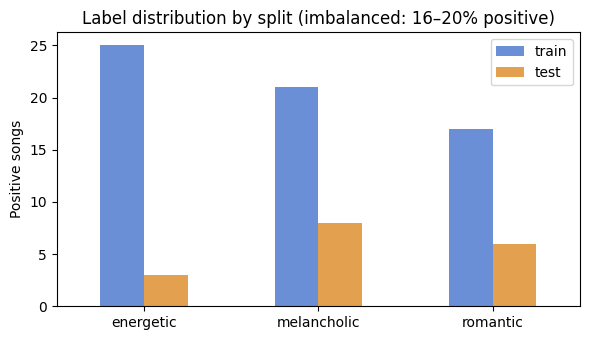

In [14]:
LABEL_RULES = {
    "energetic":   {"dance", "party", "parties", "groovy", "funky", "energetic", "workout", "active"},
    "melancholic": {"sad", "melancholic", "nostalgic", "desperate", "heartbreak", "lonely"},
    "romantic":    {"love", "romantic", "in love", "crush", "flirty"},
}
LABELS = list(LABEL_RULES)
for label, keywords in LABEL_RULES.items():
    data[label] = data["tag_list"].apply(lambda ts: int(bool(set(ts) & keywords)))

dist = pd.DataFrame({
    "all songs": data[LABELS].sum(),
    "train": data.loc[train_idx, LABELS].sum(),
    "test": data.loc[test_idx, LABELS].sum(),
    "positive rate": data[LABELS].mean().round(2)})
display(dist)

ax = dist[["train", "test"]].plot.bar(rot=0, figsize=(6, 3.5), color=["#6b8fd6", "#e3a04f"])
ax.set_ylabel("Positive songs"); ax.set_title("Label distribution by split (imbalanced: 16–20% positive)")
plt.tight_layout(); plt.savefig(FIG / "label_distribution.png", dpi=150); plt.show()

**Class imbalance.** Only 16–20% of songs are positive for each label, and the test set has just **3 energetic, 8
melancholic and 6 romantic** songs. A model that always says "no" would be ~80% *accurate* and completely useless, so I
never use accuracy here. Instead I:
* report **precision, recall and F1 for the positive class**,
* use `class_weight="balanced"`, which makes mistakes on the rare "yes" songs cost more during training,
* treat **5-fold cross-validated F1 on the 115 training songs** as my main comparison. With only 3 energetic test songs,
  one song flips test F1 by a lot, so the test set is a final check, not the judge.

### The models (and the math)

Notation: $\mathbf{x}_i$ is song $i$'s feature vector, $y_i\in\{0,1\}$ says whether I gave it the label (e.g. *energetic*).

**Standardization.** Tempo is ~100, RMS is ~0.1 and the spectral centroid is ~2500 Hz. Without rescaling, the
centroid would dominate any distance or weight just because its numbers are bigger. So each feature $j$ becomes
$z_{j}=(x_{j}-\mu_j)/\sigma_j$, with the mean $\mu_j$ and std $\sigma_j$ computed **on the training folds only** (inside the
pipeline, so even cross-validation doesn't leak).

**Logistic regression** gives each song a probability of being, say, energetic:
$$P(y_i=1\mid\mathbf{x}_i)=\sigma(\mathbf{w}^\top\mathbf{x}_i+b),\qquad \sigma(z)=\frac{1}{1+e^{-z}}$$
Each weight $w_j$ says how much feature $j$ pushes a song toward "yes" (positive) or "no" (negative). It is trained by minimizing
the class-weighted log loss plus an L2 penalty that keeps the weights small:
$$\min_{\mathbf{w},b}\;\frac{1}{2C}\lVert\mathbf{w}\rVert^2-\sum_i c_{y_i}\big[y_i\log\hat p_i+(1-y_i)\log(1-\hat p_i)\big],\qquad c_y=\frac{n}{2\,n_y}$$
$\hat p_i$ is the predicted probability, $c_y$ is the balancing weight (rare class gets a bigger weight) and $C$ controls how
strong the penalty is (small $C$ = simpler model). Logistic regression combines the features using learned weights. Because this combination is linear, it cannot automatically capture more complicated interactions between audio features unless I explicitly add them. This is one reason I also tried a decision tree and an RBF SVM.

**Decision tree** asks a sequence of yes/no questions like "is tempo > 118?" and picks, at each step, the question that makes
the groups purest, measured by Gini impurity $G=1-\sum_k p_k^2$ ($p_k$ = fraction of songs in the group with class $k$;
$G=0$ means the group is all one class). `max_depth` and `min_samples_leaf` stop it from memorizing my 115 songs.

**SVM (RBF kernel)** looks for the boundary between "yes" and "no" songs with the widest possible margin:
$$\min_{\mathbf{w},b,\xi}\;\tfrac12\lVert\mathbf{w}\rVert^2+C\sum_i c_{y_i}\xi_i\quad\text{s.t. } y_i(\mathbf{w}^\top\phi(\mathbf{x}_i)+b)\ge1-\xi_i,\;\xi_i\ge0$$
(here $y_i\in\{-1,+1\}$). The slack $\xi_i$ lets a song be on the wrong side at a cost $C$. The RBF kernel
$k(\mathbf{x},\mathbf{x}')=\exp(-\gamma\lVert\mathbf{x}-\mathbf{x}'\rVert^2)$ measures how similar two songs are, so the boundary can curve around clusters of similar-sounding songs instead of being a straight line.

**Baselines.** *Majority* always says "no". *Stratified* randomly says "yes" at the training positive rate. A real model has to beat both.

**Metrics.** With $TP$ = songs correctly called energetic, $FP$ = wrongly called energetic, $FN$ = energetic songs the model missed:
$$P=\frac{TP}{TP+FP}\;\text{(when it says yes, is it right?)}\qquad R=\frac{TP}{TP+FN}\;\text{(how many of my energetic songs did it find?)}\qquad F_1=\frac{2PR}{P+R}$$

**Model selection.** For every label × feature set × model, `GridSearchCV` with stratified 5-fold CV on the training songs
picks the hyperparameters with the best F1. That setting is refit on all 115 songs and scored once on the 30 test songs.

In [15]:
FEATURE_SETS = {"Handcrafted (33-d)": HAND_COLS, "CLAP (512-d)": CLAP_COLS}

MODELS = {
    "Majority baseline": (DummyClassifier(strategy="most_frequent"), {}),
    "Stratified baseline": (DummyClassifier(strategy="stratified", random_state=SEED), {}),
    "Logistic regression": (Pipeline([("scale", StandardScaler()),
                                      ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))]),
                            {"clf__C": [0.01, 0.1, 1, 10]}),
    "Decision tree": (DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                      {"max_depth": [2, 3, 5, None], "min_samples_leaf": [1, 5]}),
    "SVM (RBF)": (Pipeline([("scale", StandardScaler()),
                            ("clf", SVC(kernel="rbf", class_weight="balanced"))]),
                  {"clf__C": [0.1, 1, 10]}),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cls_rows, cls_preds = [], {}

for fs_name, cols in FEATURE_SETS.items():
    X_tr, X_te = data.loc[train_idx, cols].to_numpy(), data.loc[test_idx, cols].to_numpy()
    for label in LABELS:
        y_tr, y_te = data.loc[train_idx, label].to_numpy(), data.loc[test_idx, label].to_numpy()
        for m_name, (estimator, grid) in MODELS.items():
            if grid:
                search = GridSearchCV(estimator, grid, scoring="f1", cv=cv)
                search.fit(X_tr, y_tr)
                model, best_params = search.best_estimator_, search.best_params_
                idx = search.best_index_
                cv_f1 = np.array([search.cv_results_[f"split{k}_test_score"][idx] for k in range(5)])
            else:
                cv_f1 = cross_val_score(estimator, X_tr, y_tr, scoring="f1", cv=cv)
                model, best_params = estimator.fit(X_tr, y_tr), {}
            y_hat = model.predict(X_te)
            p, r, f1, _ = precision_recall_fscore_support(y_te, y_hat, average="binary", zero_division=0)
            cls_preds[(fs_name, label, m_name)] = y_hat
            cls_rows.append({"features": fs_name, "label": label, "model": m_name,
                             "CV F1 mean": cv_f1.mean(), "CV F1 std": cv_f1.std(),
                             "test precision": p, "test recall": r, "test F1": f1,
                             "best params": json.dumps({k.replace("clf__", ""): v for k, v in best_params.items()})})

cls_results = pd.DataFrame(cls_rows)
cls_results.to_csv(OUT / "classification_results.csv", index=False)
print("Trained", len(cls_results), "label × feature-set × model combinations")

Trained 30 label × feature-set × model combinations


In [16]:
# Macro average over the three labels: one row per model × feature set
summary_A = (cls_results.groupby(["features", "model"], sort=False)
             [["CV F1 mean", "test precision", "test recall", "test F1"]].mean().round(3))
summary_A.columns = ["CV F1 (macro)", "test precision (macro)", "test recall (macro)", "test F1 (macro)"]
display(summary_A)

# Full per-label table
display(cls_results.round(3))

CV F1 (macro)  test precision (macro)  \
features           model                                                        
Handcrafted (33-d) Majority baseline            0.000                   0.000   
                   Stratified baseline          0.153                   0.306   
                   Logistic regression          0.301                   0.236   
                   Decision tree                0.311                   0.257   
                   SVM (RBF)                    0.291                   0.279   
CLAP (512-d)       Majority baseline            0.000                   0.000   
                   Stratified baseline          0.153                   0.306   
                   Logistic regression          0.361                   0.275   
                   Decision tree                0.320                   0.251   
                   SVM (RBF)                    0.384                   0.357   

                                        test recall (macro)  test F1 (macro)  
features           model                                                      
Handcrafted (33-d) Majority baseline                  0.000            0.000  
                   Stratified baseline                0.153            0.204  
                   Logistic regression                0.500            0.315  
                   Decision tree                      0.347            0.292  
                   SVM (RBF)                          0.556            0.345  
CLAP (512-d)       Majority baseline                  0.000            0.000  
                   Stratified baseline                0.153            0.204  
                   Logistic regression                0.431            0.333  
                   Decision tree                      0.389            0.305  
                   SVM (RBF)                          0.722            0.458

,features,label,model,CV F1 mean,CV F1 std,test precision,test recall,test F1,best params
0,Handcrafted (33-d),energetic,Majority baseline,0.000,0.000,0.000,0.000,0.000,{}
1,Handcrafted (33-d),energetic,Stratified baseline,0.133,0.109,0.000,0.000,0.000,{}
2,Handcrafted (33-d),energetic,Logistic regression,0.355,0.076,0.000,0.000,0.000,"{""C"": 0.01}"
3,Handcrafted (33-d),energetic,Decision tree,0.367,0.130,0.000,0.000,0.000,"{""max_depth"": 2, ""min_samples_leaf"": 5}"
4,Handcrafted (33-d),energetic,SVM (RBF),0.403,0.071,0.000,0.000,0.000,"{""C"": 0.1}"
5,Handcrafted (33-d),melancholic,Majority baseline,0.000,0.000,0.000,0.000,0.000,{}
6,Handcrafted (33-d),melancholic,Stratified baseline,0.144,0.198,0.250,0.125,0.167,{}
7,Handcrafted (33-d),melancholic,Logistic regression,0.294,0.122,0.333,0.500,0.400,"{""C"": 1}"
8,Handcrafted (33-d),melancholic,Decision tree,0.349,0.126,0.200,0.375,0.261,"{""max_depth"": 3, ""min_samples_leaf"": 1}"
9,Handcrafted (33-d),melancholic,SVM (RBF),0.308,0.024,0.267,1.000,0.421,"{""C"": 0.1}"


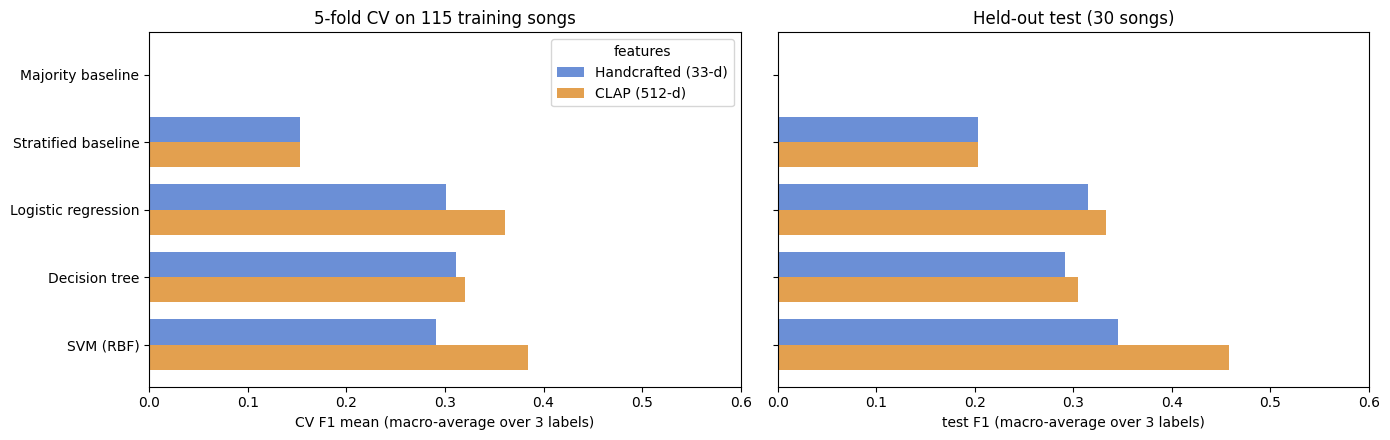

In [17]:
model_order = list(MODELS)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, metric in zip(axes, ["CV F1 mean", "test F1"]):
    table = cls_results.pivot_table(index="model", columns=["features"], values=metric, aggfunc="mean").loc[model_order, list(FEATURE_SETS)]
    table.plot.barh(ax=ax, color=["#6b8fd6", "#e3a04f"], width=0.75)
    ax.set_xlabel(f"{metric} (macro-average over 3 labels)"); ax.set_ylabel("")
    ax.set_title("5-fold CV on 115 training songs" if metric.startswith("CV") else "Held-out test (30 songs)")
    ax.invert_yaxis(); ax.set_xlim(0, 0.6)
axes[1].get_legend().remove()
plt.tight_layout(); plt.savefig(FIG / "classification_comparison.png", dpi=150); plt.show()

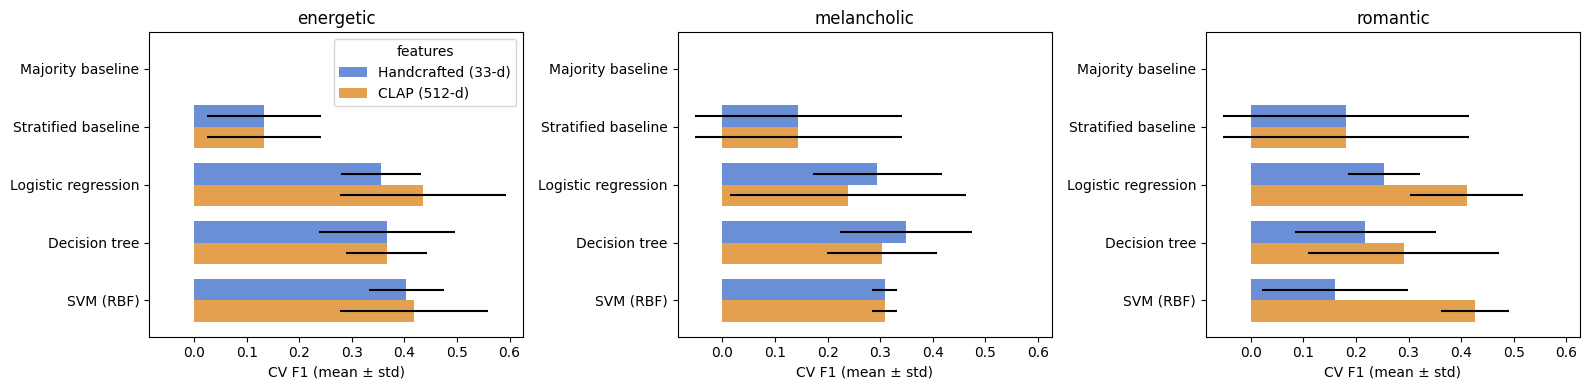

In [18]:
# Per-label CV F1 with fold-to-fold spread (error bars = std over 5 folds)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True)
for ax, label in zip(axes, LABELS):
    sub = cls_results[cls_results.label == label]
    piv_m = sub.pivot(index="model", columns="features", values="CV F1 mean").loc[model_order, list(FEATURE_SETS)]
    piv_s = sub.pivot(index="model", columns="features", values="CV F1 std").loc[model_order, list(FEATURE_SETS)]
    piv_m.plot.barh(ax=ax, xerr=piv_s, color=["#6b8fd6", "#e3a04f"], width=0.75, legend=(label == LABELS[0]))
    ax.set_title(label); ax.set_xlabel("CV F1 (mean ± std)"); ax.set_ylabel(""); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(FIG / "classification_per_label_cv.png", dpi=150); plt.show()

### So... did it work? Kind of!

* **Every real model beats both baselines.** Majority gets F1 = 0 (it never says yes), stratified gets 0.153 in CV, and all
  three models land around **0.29–0.38 macro CV F1, roughly double random guessing**. So there *is* signal in the audio.
* **CLAP features help logistic regression and the SVM** (CV F1 0.301 → 0.361 and 0.291 → 0.384), but barely change the
  decision tree (0.311 → 0.320). My guess is that a tree splits on one feature at a time, while CLAP's information is spread over
  many of its 512 numbers. Any single CLAP dimension doesn't mean much on its own.
* **I can't really rank LR vs. tree vs. SVM.** The fold-to-fold standard deviation is often 0.1 or more (error bars above),
  which is bigger than most of the gaps between models. The handcrafted → CLAP improvement for LR/SVM is the more consistent pattern.
* **The test set is noisy, as expected.** The best overall combo, SVM + CLAP, gets 0.458 macro test F1, but look at
  *energetic*: every handcrafted model scores **0 test F1** even though their CV F1 is ~0.36–0.40. With only 3 energetic
  test songs, missing them all is easy. This is exactly why I picked models by CV and not by test score.

### 5-fold reality check: which handcrafted features actually help? (ablation)
After comparing the models, I wanted to understand whether adding more audio features actually improved predictions. Instead of assuming that more features would help, I ran an ablation study to test which groups of features were contributing useful information. I kept the logistic regression model and its settings fixed (C=1, balanced classes, standardized inputs), then changed only the input features to make the comparison fair.
1. **Basic (7-d):** tempo, onset strength, RMS mean/std, spectral centroid, bandwidth, zero-crossing rate. These are the
   "intuitive" features, the ones I'd expect to matter for something like *energetic*.
2. **All handcrafted (33-d):** basic + the 26 MFCC summaries.
3. **All handcrafted minus tempo-related (31-d):** drops `tempo` and `onset_mean`, to test whether rhythm info is pulling its weight.
4. **MFCCs only (26-d):** just timbre, as a sanity check for *where* the signal comes from.

Same labels, same 115 training songs, no test songs. Because one 5-fold split on 115 songs is noisy, I use **5-fold CV
repeated 5 times (25 folds)**. Every feature set sees the *exact same* 25 folds (the folds only depend on the labels and the seed),
so I can also compare them fold by fold (a paired comparison).

In [19]:
TEMPO_COLS = ["tempo", "onset_mean"]
BASIC_COLS = ["tempo", "onset_mean", "rms_mean", "rms_std", "centroid_mean", "bandwidth_mean", "zcr_mean"]
ABLATION_SETS = {
    "Basic (7-d)": BASIC_COLS,
    "All handcrafted (33-d)": HAND_COLS,
    "All minus tempo/onset (31-d)": [c for c in HAND_COLS if c not in TEMPO_COLS],
    "MFCCs only (26-d)": [c for c in HAND_COLS if c.startswith("mfcc")],
}
ablation_model = Pipeline([("scale", StandardScaler()),
                           ("clf", LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))])
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)   # same 25 folds for every feature set

abl_scores = {}   # (feature set, label) -> 25 fold F1 scores
for fs_name, cols in ABLATION_SETS.items():
    X_tr = data.loc[train_idx, cols].to_numpy()
    for label in LABELS:
        y_tr = data.loc[train_idx, label].to_numpy()
        abl_scores[(fs_name, label)] = cross_val_score(clone(ablation_model), X_tr, y_tr, scoring="f1", cv=rcv)

abl = pd.DataFrame([{"feature set": fs, "label": lb, "CV F1 mean": s.mean(), "CV F1 std": s.std()}
                    for (fs, lb), s in abl_scores.items()])
abl_table = abl.pivot(index="feature set", columns="label", values="CV F1 mean").loc[list(ABLATION_SETS), LABELS]
abl_table["macro"] = abl_table.mean(axis=1)
abl.to_csv(OUT / "ablation_results.csv", index=False)
display(abl_table.round(3))

# Paired, fold-by-fold comparison against the full 33-d set
print("Fold-by-fold vs. all handcrafted (positive = better than full set):")
for fs_name in ABLATION_SETS:
    if fs_name == "All handcrafted (33-d)":
        continue
    for label in LABELS:
        d = abl_scores[(fs_name, label)] - abl_scores[("All handcrafted (33-d)", label)]
        print(f"  {fs_name:30s} {label:12s} mean diff {d.mean():+.3f} | better in {(d > 0).sum():2d}/25 folds, worse in {(d < 0).sum():2d}/25")

label,energetic,melancholic,romantic,macro
feature set,,,,
Basic (7-d),0.298,0.336,0.257,0.297
All handcrafted (33-d),0.210,0.289,0.173,0.224
All minus tempo/onset (31-d),0.218,0.296,0.208,0.241
MFCCs only (26-d),0.252,0.267,0.182,0.234


Fold-by-fold vs. all handcrafted (positive = better than full set):
  Basic (7-d)                    energetic    mean diff +0.088 | better in 18/25 folds, worse in  5/25
  Basic (7-d)                    melancholic  mean diff +0.047 | better in 13/25 folds, worse in 10/25
  Basic (7-d)                    romantic     mean diff +0.084 | better in 14/25 folds, worse in  6/25
  All minus tempo/onset (31-d)   energetic    mean diff +0.008 | better in  8/25 folds, worse in  3/25
  All minus tempo/onset (31-d)   melancholic  mean diff +0.007 | better in 11/25 folds, worse in  9/25
  All minus tempo/onset (31-d)   romantic     mean diff +0.035 | better in 10/25 folds, worse in  2/25
  MFCCs only (26-d)              energetic    mean diff +0.042 | better in 11/25 folds, worse in  4/25
  MFCCs only (26-d)              melancholic  mean diff -0.022 | better in 10/25 folds, worse in 10/25
  MFCCs only (26-d)              romantic     mean diff +0.009 | better in 10/25 folds, worse in  9/25


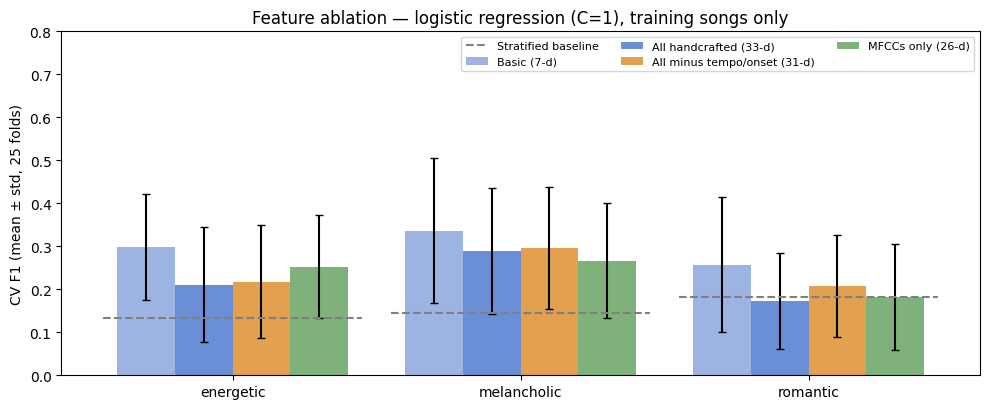

In [20]:
fig, ax = plt.subplots(figsize=(10, 4.2))
colors = ["#9db4e3", "#6b8fd6", "#e3a04f", "#7fb27a"]
width = 0.2
for k, (fs_name, color) in enumerate(zip(ABLATION_SETS, colors)):
    means = [abl_scores[(fs_name, lb)].mean() for lb in LABELS]
    stds = [abl_scores[(fs_name, lb)].std() for lb in LABELS]
    ax.bar(np.arange(len(LABELS)) + (k - 1.5) * width, means, width, yerr=stds, capsize=3, color=color, label=fs_name)
strat = cls_results[(cls_results.model == "Stratified baseline") & (cls_results.features == "Handcrafted (33-d)")]
for j, lb in enumerate(LABELS):
    ax.hlines(strat.set_index("label").loc[lb, "CV F1 mean"], j - 0.45, j + 0.45, colors="grey", linestyles="--",
              label="Stratified baseline" if j == 0 else None)
ax.set_xticks(range(len(LABELS)), LABELS)
ax.set_ylabel("CV F1 (mean ± std, 25 folds)")
ax.set_title("Feature ablation — logistic regression (C=1), training songs only")
ax.legend(fontsize=8, ncol=3, loc="upper right"); ax.set_ylim(0, 0.8)
plt.tight_layout(); plt.savefig(FIG / "feature_ablation.png", dpi=150); plt.show()

What the ablation shows: The ablation study surprised me because I expected that giving the model more information would help. Instead, logistic regression performed best with just seven basic acoustic features, achieving an average cross-validation F1 of 0.297, compared with 0.224 using all 33 handcrafted features. This suggests that the extra MFCC features were not helping this particular model on my small dataset. They may contain redundant information or make it harder to learn patterns that generalize. Removing tempo and onset from the full feature set only improved F1 slightly, from 0.224 to 0.241, so I cannot conclude that rhythm features are unimportant. What I learned is that feature selection matters as much as model choice, and that I should test whether additional variables actually improve performance rather than assuming they will.

### What is the logistic regression actually looking at? (coefficients)

Because the inputs are standardized, a logistic regression weight $w_j$ means "how much one standard deviation more of feature
$j$ changes the log-odds of the label". Positive pushes toward *yes*, negative toward *no*. I fit the model (`C=1`, all 33
handcrafted features) on the 115 training songs and plot the 8 biggest weights for each label.

A single fit on 115 songs can be pretty random, so I also refit it on each of the 25 CV training folds and count how often
each weight keeps the **same sign**. A weight that flips sign half the time shouldn't be trusted.

*Limitation:* many of these features are correlated (e.g. RMS and onset strength, or neighbouring MFCCs), so the model can
split credit between them almost arbitrarily. These weights show what this model *uses*, not what *causes* a song to feel energetic.

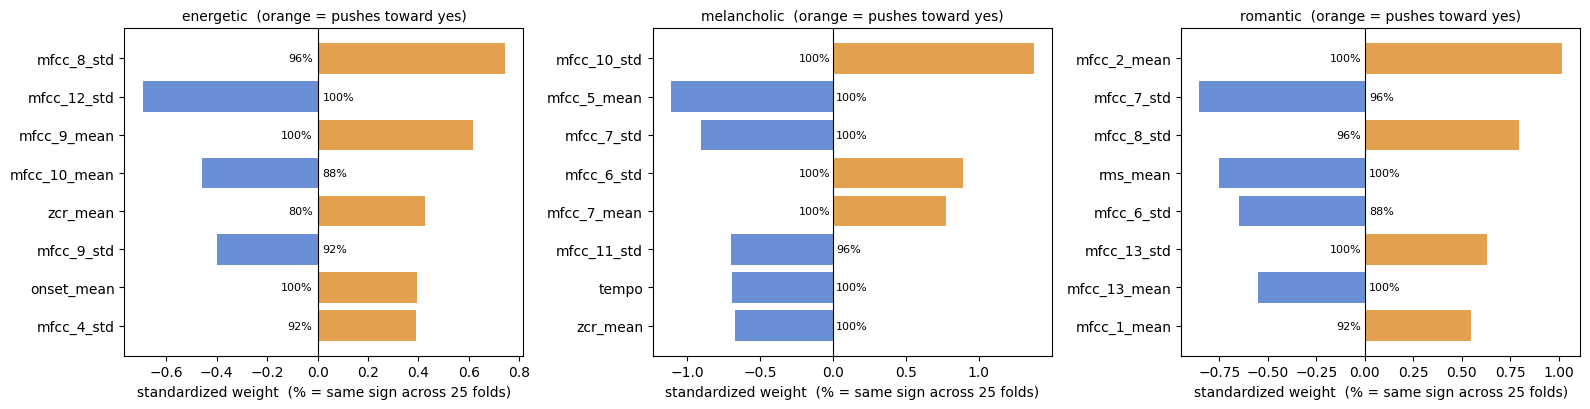

energetic    mfcc_8_std +0.74 (96%) | mfcc_12_std -0.69 (100%) | mfcc_9_mean +0.62 (100%) | mfcc_10_mean -0.46 (88%) | zcr_mean +0.43 (80%)
melancholic  mfcc_10_std +1.38 (100%) | mfcc_5_mean -1.11 (100%) | mfcc_7_std -0.91 (100%) | mfcc_6_std +0.89 (100%) | mfcc_7_mean +0.77 (100%)
romantic     mfcc_2_mean +1.02 (100%) | mfcc_7_std -0.85 (96%) | mfcc_8_std +0.80 (96%) | rms_mean -0.75 (100%) | mfcc_6_std -0.65 (88%)


In [21]:
coef_rows = []
for label in LABELS:
    X_tr = data.loc[train_idx, HAND_COLS].to_numpy()
    y_tr = data.loc[train_idx, label].to_numpy()
    full = clone(ablation_model).fit(X_tr, y_tr).named_steps["clf"].coef_[0]
    folds = np.array([clone(ablation_model).fit(X_tr[tr], y_tr[tr]).named_steps["clf"].coef_[0]
                      for tr, _ in rcv.split(X_tr, y_tr)])
    sign_agree = (np.sign(folds) == np.sign(full)).mean(axis=0)
    for feat, w, s in zip(HAND_COLS, full, sign_agree):
        coef_rows.append({"label": label, "feature": feat, "weight": w, "same sign in folds": s})
coefs = pd.DataFrame(coef_rows)
coefs.to_csv(OUT / "logreg_coefficients.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, label in zip(axes, LABELS):
    top = coefs[coefs.label == label].reindex(coefs[coefs.label == label].weight.abs().sort_values(ascending=False).index).head(8)
    ax.barh(top.feature, top.weight, color=["#e3a04f" if w > 0 else "#6b8fd6" for w in top.weight])
    for y_pos, (w, s) in enumerate(zip(top.weight, top["same sign in folds"])):
        ax.text(-0.02 if w > 0 else 0.02, y_pos, f"{s:.0%}", va="center", ha="right" if w > 0 else "left", fontsize=8)
    ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis()
    ax.set_title(f"{label}  (orange = pushes toward yes)", fontsize=10)
    ax.set_xlabel("standardized weight  (% = same sign across 25 folds)")
plt.tight_layout(); plt.savefig(FIG / "logreg_coefficients.png", dpi=150); plt.show()

for label in LABELS:
    top = coefs[coefs.label == label].sort_values("weight", key=abs, ascending=False).head(5)
    print(f"{label:12s}", " | ".join(f"{f} {w:+.2f} ({s:.0%})" for f, w, s in
                                    zip(top.feature, top.weight, top["same sign in folds"])))

### What the weights suggest

I wanted to look inside the logistic regression model instead of only comparing its F1 scores. Since the audio features were standardized, I can compare the relative size of the coefficients within each model. A positive coefficient pushes the prediction toward a label, while a negative coefficient pushes it away, assuming the other features stay constant.

For **energetic**, `mfcc_8_std` has a strong positive weight (+0.74), while `mfcc_12_std` has a negative weight (−0.69). For **melancholic**, `mfcc_10_std` has the largest positive weight (+1.38), while `mfcc_5_mean` has a negative weight (−1.11). For **romantic**, `mfcc_2_mean` has a positive weight (+1.02), while `mfcc_7_std` has a negative weight (−0.85).

The percentages next to the bars show how often each coefficient kept the same sign across 25 cross-validation fits. Several important features were consistent in 96–100% of those fits, suggesting that the direction of their relationship with the label was relatively stable.

What surprised me is that many of the strongest predictors are **MFCC features**, which summarize aspects of a song's timbre, rather than obvious features like tempo or loudness. This suggests that differences in sound texture might help distinguish my aesthetic categories. However, individual MFCC coefficients are difficult to interpret musically, so I cannot conclude that a specific MFCC directly causes a song to feel romantic or melancholic.

This analysis also helps explain why feature selection matters. Some features show consistent relationships with my labels, but that does not mean using all 33 features produces the best predictions. My ablation experiment tests that question more directly.

### Error analysis: which songs did it get wrong, and why?

For each label I take the model × feature set with the **best CV F1** (chosen on training data, not test), then look at its
test confusion matrix and the actual songs it messed up.

,features,model,best params,CV F1 mean,test precision,test recall,test F1
label,,,,,,,
energetic,CLAP (512-d),Logistic regression,"{""C"": 0.01}",0.435,0.200,0.333,0.250
melancholic,Handcrafted (33-d),Decision tree,"{""max_depth"": 3, ""min_samples_leaf"": 1}",0.349,0.200,0.375,0.261
romantic,CLAP (512-d),SVM (RBF),"{""C"": 1}",0.427,0.556,0.833,0.667


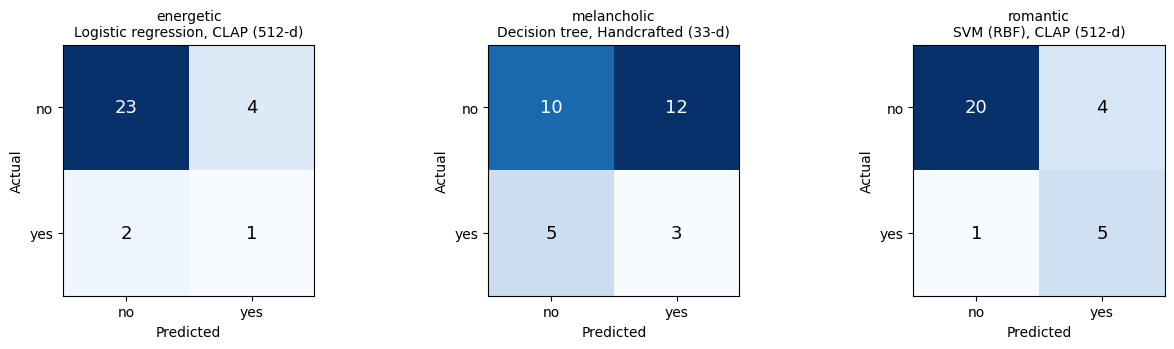

In [22]:
real_models = ["Logistic regression", "Decision tree", "SVM (RBF)"]
best_A = (cls_results[cls_results.model.isin(real_models)]
          .sort_values("CV F1 mean", ascending=False).groupby("label").head(1).set_index("label").loc[LABELS])
display(best_A[["features", "model", "best params", "CV F1 mean", "test precision", "test recall", "test F1"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, label in zip(axes, LABELS):
    row = best_A.loc[label]
    y_te = data.loc[test_idx, label].to_numpy()
    cm = confusion_matrix(y_te, cls_preds[(row.features, label, row.model)], labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for (a, b), v in np.ndenumerate(cm):
        ax.text(b, a, v, ha="center", va="center", fontsize=13, color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["no", "yes"]); ax.set_yticks([0, 1], ["no", "yes"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"{label}\n{row.model}, {row.features}", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "classification_confusion.png", dpi=150); plt.show()

In [23]:
# Which test songs were misclassified, and what did I actually tag them?
for label in LABELS:
    row = best_A.loc[label]
    y_te = data.loc[test_idx, label].to_numpy()
    y_hat = cls_preds[(row.features, label, row.model)]
    print(f"\n=== {label.upper()} ({row.model}, {row.features})")
    for kind, mask in [("False negatives (I said yes, model said no)", (y_te == 1) & (y_hat == 0)),
                       ("False positives (I said no, model said yes)", (y_te == 0) & (y_hat == 1))]:
        print(f"  {kind}: {mask.sum()}")
        for i in test_idx[mask][:6]:
            print(f"    - {data.title[i]} — {data.artist[i]} | my tags: {', '.join(data.tag_list[i][:8])}")


=== ENERGETIC (Logistic regression, CLAP (512-d))
  False negatives (I said yes, model said no): 2
    - Get Down On It — Kool & The Gang | my tags: funky, disco, cool, happy, funny, weekend, free, life is good
    - You Should Be Dancing — Bee Gees | my tags: cinematic, groovy, night walk, cool, sleazy, having fun, bars, happy
  False positives (I said no, model said yes): 4
    - Get Busy — Mr. Lee | my tags: vogue, fashion, 90s house, cars, beating, people, flex, working
    - La Fessée — Claire Laffut | my tags: fashion, chic, streetstyle, cafés, croissants, influencer vibe, normal outfits, daytime
    - Passin' Me By — The Pharcyde | my tags: old-school hip-hop, vintage, fashiony, brown, dark, streets, favelas, graffiti
    - I Like It — Enrique Iglesias, Pitbull | my tags: party life, cool, happy, uplifted, strong, confident, sexy, hot

=== MELANCHOLIC (Decision tree, Handcrafted (33-d))
  False negatives (I said yes, model said no): 5
    - I'm not in love — 10cc | my tags: sad

Reading through the mistakes, a lot of them are honestly **my labels' fault**, not the model's:

* **Energetic false positives** include *Get Busy* (I tagged it "dancing", "90s house", "moving") and *I Like It*
  ("party life", "uplifted"). These songs *are* energetic! But my keyword rule only matches the exact words "dance" and "party",
  so "dancing" and "party life" don't count, and the song ends up labeled *not energetic*. The model heard it right, and my rule
  marked it wrong.
* **Melancholic** is the weakest label (12 false positives). My rule counts "nostalgic" as melancholic, so *Déjà Vu*
  (beach, aquapark, party, nostalgic 2000s Romanian pop) is labeled melancholic even though it sounds like summer.
  "Nostalgic" for me is often about *memories*, not about sound being sad.
* **Romantic** false positives are songs that *sound* tender: *Ode to my family* (longing, missing) and *Lost & Found*
  (soul, self-care). The model confuses "emotional and soft" with "romantic", which is a pretty human mistake.

So part of the ceiling here is label noise from my keyword rules. A fairer next version would match word stems
(dance/dancing) and maybe drop "nostalgic" from melancholic.

# Part B: Recommending my exact personal tags

This is the version 777 Radio actually needs: **for a song the model has never heard, suggest the 10 tags I'd most likely
write.** The models *choose* from tags I've already used on the 115 training songs (644 candidates); they don't invent new
words. That's on purpose: the app matches images against *my* vocabulary, and letting a model pick tags that only exist on
test songs would leak the answers.

### Methods
* **Random tags**: 10 random candidates. The floor.
* **Popularity baseline**: my 10 most-used training tags, the *same list for every song*. Annoyingly strong, because my common tags are everywhere.
* **kNN (k = 5)**: find the 5 training songs that sound most similar and take their tags, weighted by similarity. kNN has no
  training step; it just stores the songs and compares.
* **kNN + popularity prior**: mix "what similar songs have" with "what I usually write" (explained below).
* **CLAP zero-shot**: no learning from my data at all. Compare the song's audio embedding with the CLAP *text* embedding of
  each tag ("a song with a {tag} vibe") and pick the 10 closest. Plus a calibrated version (explained in the results).

### Math

**Cosine similarity** measures how alike two songs sound, using the angle between their vectors:
$$\text{sim}(\mathbf{x}_i,\mathbf{x}_j)=\frac{\mathbf{x}_i\cdot\mathbf{x}_j}{\lVert\mathbf{x}_i\rVert\,\lVert\mathbf{x}_j\rVert}$$
It's 1 if they point the same way and around 0 if they're unrelated. I normalize every vector to length 1, so this is just a
dot product. Handcrafted features are standardized with training statistics first (same reason as Part A).

**kNN + popularity prior.** Plain kNN turned out to copy one-off tags from neighbours ("diamonds", "mountains") that almost
never repeat. So the score for tag $t$ on a new song $\mathbf{x}$ blends two things:
$$s(t\mid\mathbf{x})=\alpha\underbrace{\frac{\sum_{j\in N_k(\mathbf{x})}w_j\,y_{jt}}{\sum_{j\in N_k(\mathbf{x})}w_j}}_{\text{share of similar songs I tagged }t}+(1-\alpha)\underbrace{\frac{f_t}{\max_{t'}f_{t'}}}_{\text{how often I use }t}$$
$N_k(\mathbf{x})$ is the $k=15$ most similar training songs, $w_j=\max(\text{sim}(\mathbf{x},\mathbf{x}_j),0)$ is how similar
neighbour $j$ is, $y_{jt}=1$ if I tagged song $j$ with $t$, and $f_t$ is the number of training songs with tag $t$. The top-10 tags
by $s$ are the recommendation. $\alpha=0$ ignores the audio completely (pure popularity), $\alpha=1$ is pure neighbours.

**Metrics.** For the 10 recommended tags $\hat T_{10}$ and my real tags $T$:
$$P@10=\frac{|\hat T_{10}\cap T|}{10}\qquad R@10=\frac{|\hat T_{10}\cap T|}{|T|}$$
P@10 = 0.1 means one of the ten suggestions is a tag I actually wrote.

**Soft precision (my own metric).** Exact matching is harsh: suggesting "dance" when I wrote "dancing" counts as a miss.
So for each suggested tag I find my closest real tag in meaning, using an **independent** sentence-embedding model $e(\cdot)$
(MiniLM, not CLAP, so CLAP isn't grading its own homework), and average:
$$\text{SoftP}=\frac{1}{10}\sum_{\hat t\in\hat T_{10}}\max_{t\in T}\cos\big(e(\hat t),e(t)\big)$$
This is only a **proxy**. "Close in a language model's embedding space" is not the same as "a tag I'd agree with", and I
haven't validated it against my own judgement.

**Tag variety** = how many different tags a method recommends across all 30 test songs. **Ceiling** =
$\min(|T\cap V_{train}|,10)/|T|$, the best recall@10 any method limited to the training vocabulary $V_{train}$ could get.

In [24]:
train_tags = Counter(t for i in train_idx for t in data.tags[i])
vocab = sorted(train_tags)                      # candidate tags: training songs only
vidx = {v: j for j, v in enumerate(vocab)}

def unit(M):
    return M / np.linalg.norm(M, axis=1, keepdims=True)

# Handcrafted: standardize with TRAINING mean/std, then unit-normalize for cosine similarity
Xh = data[HAND_COLS].fillna(data.loc[train_idx, HAND_COLS].median())
mu, sd = Xh.loc[train_idx].mean(), Xh.loc[train_idx].std()
H = unit(((Xh - mu) / sd).to_numpy())
A = unit(data[CLAP_COLS].to_numpy())

# Binary song × tag matrix for training songs
Y = np.zeros((len(data), len(vocab)))
for i in train_idx:
    for t in data.tags[i]:
        Y[i, vidx[t]] = 1

ceiling = [min(len(set(data.tags[i]) & set(vocab)), K) / len(data.tags[i]) for i in test_idx]
print(f"Candidate tags: {len(vocab)} | max achievable recall@10 on test songs: {np.mean(ceiling):.3f}")

Candidate tags: 644 | max achievable recall@10 on test songs: 0.604


In [25]:
# CLAP text embeddings for every candidate tag (cached; the model loads only if tags are missing)
def clap_text_embeddings(tags, template="a song with a {} vibe"):
    cache = pd.read_csv(CLAP_TEXT_CACHE, dtype={"tag": str}, keep_default_na=False).set_index("tag") if CLAP_TEXT_CACHE.exists() else pd.DataFrame()
    missing = [t for t in tags if t not in cache.index]
    if missing:
        c = load_clap()
        new = []
        with c["torch"].no_grad():
            for s in range(0, len(missing), 64):
                inp = c["proc"](text=[template.format(t) for t in missing[s:s + 64]], return_tensors="pt", padding=True)
                inp = {k: v.to(c["device"]) for k, v in inp.items()}
                new.append(as_emb(c["model"].get_text_features(**inp)).cpu().numpy())
        new = pd.DataFrame(np.vstack(new), index=pd.Index(missing, name="tag"))
        new.columns = [str(c_) for c_ in new.columns]
        cache = pd.concat([cache, new]) if len(cache) else new
        cache.reset_index().to_csv(CLAP_TEXT_CACHE, index=False)
    return cache.loc[tags].to_numpy(dtype=float)

T = unit(clap_text_embeddings(vocab))
print("CLAP text embeddings:", T.shape)

CLAP text embeddings: (644, 512)


In [26]:
def popularity(i):
    return [t for t, _ in train_tags.most_common(K)]

def knn(E, k=5):
    def predict(i):
        sims = E[train_idx] @ E[i]
        score = Counter()
        for r in np.argsort(-sims)[:k]:
            for t in data.tags[train_idx[r]]:
                score[t] += max(sims[r], 1e-6)
        return [t for t, _ in score.most_common(K)]
    return predict

def knn_prior_scores(E, i, k=15, alpha=0.5, exclude=None):
    pool = train_idx if exclude is None else train_idx[train_idx != exclude]
    prior = Y[pool].mean(0)
    prior = prior / prior.max()
    sims = E[pool] @ E[i]
    nn = np.argsort(-sims)[:k]
    w = np.maximum(sims[nn], 0) + 1e-9
    vote = (w[:, None] * Y[pool[nn]]).sum(0) / w.sum()
    return alpha * vote + (1 - alpha) * prior

def make_knn_prior(E, alpha):
    return lambda i: [vocab[j] for j in np.argsort(-knn_prior_scores(E, i, alpha=alpha))[:K]]

def clap_zero_shot(i):
    return [vocab[j] for j in np.argsort(-(T @ A[i]))[:K]]

# Calibration: z-score each tag's similarity across TRAINING songs
S_train = A[train_idx] @ T.T
mu_t, sd_t = S_train.mean(0), S_train.std(0) + 1e-9
def clap_zero_shot_calibrated(i):
    return [vocab[j] for j in np.argsort(-((T @ A[i] - mu_t) / sd_t))[:K]]

### Choosing α (leave-one-out on the training songs)

I try α ∈ {0, 0.25, 0.5, 0.75, 1}. For each value, every training song is hidden in turn and tagged using the other 114, then
I average precision@10. The test songs are never touched. This curve is basically my "learning" figure: anything above α = 0
is what the model gains by *listening*.

,Handcrafted,CLAP
alpha,,
0.00,0.087,0.087
0.25,0.103,0.102
0.50,0.108,0.113
0.75,0.111,0.114
1.00,0.091,0.105


Chosen alpha: {'Handcrafted': np.float64(0.75), 'CLAP': np.float64(0.75)}


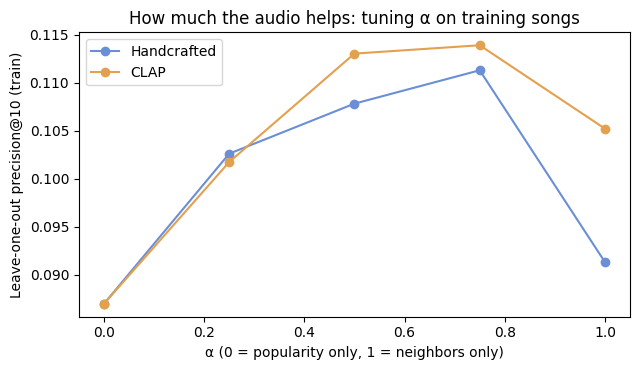

In [27]:
ALPHAS = [0, 0.25, 0.5, 0.75, 1.0]
def loo_precision(E, alpha):
    hits = []
    for i in train_idx:
        top = [vocab[j] for j in np.argsort(-knn_prior_scores(E, i, alpha=alpha, exclude=i))[:K]]
        hits.append(len(set(top) & set(data.tags[i])) / K)
    return np.mean(hits)

tuning = pd.DataFrame({name: [loo_precision(E, a) for a in ALPHAS]
                       for name, E in [("Handcrafted", H), ("CLAP", A)]}, index=ALPHAS)
tuning.index.name = "alpha"
display(tuning.round(3))
best_alpha = {name: tuning[name].idxmax() for name in tuning}
print("Chosen alpha:", best_alpha)

ax = tuning.plot(marker="o", figsize=(6.5, 3.8), color=["#6b8fd6", "#e3a04f"])
ax.set_xlabel("α (0 = popularity only, 1 = neighbors only)")
ax.set_ylabel("Leave-one-out precision@10 (train)")
ax.set_title("How much the audio helps: tuning α on training songs")
plt.tight_layout(); plt.savefig(FIG / "alpha_tuning.png", dpi=150); plt.show()

Both curves have the same shape: precision@10 goes from **0.087 at α = 0** (popularity only) up to **0.111 (handcrafted) /
0.114 (CLAP) at α = 0.75**, then drops at α = 1. So on the training songs, adding audio neighbours improves on my own habits by
about 30%. But *only* using neighbours is worse again, because then the one-off tags creep back in. Both feature sets pick α = 0.75.

In [28]:
# Soft-precision judge: an independent sentence-embedding model (not CLAP)
from sentence_transformers import SentenceTransformer
judge = SentenceTransformer("all-MiniLM-L6-v2")
_judge_cache = {}
def judge_emb(tags):
    new = [t for t in tags if t not in _judge_cache]
    if new:
        for t, e in zip(new, judge.encode(new, normalize_embeddings=True)):
            _judge_cache[t] = e
    return np.array([_judge_cache[t] for t in tags])

def soft_precision(pred, true):
    return float((judge_emb(list(pred)) @ judge_emb(sorted(true)).T).max(axis=1).mean())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [29]:
rng = np.random.default_rng(0)
methods = {
    "Random tags": lambda i: list(rng.choice(vocab, K, replace=False)),
    "Popularity baseline": popularity,
    "kNN — handcrafted (k=5)": knn(H),
    "kNN — CLAP (k=5)": knn(A),
    f"kNN+prior — handcrafted (α={best_alpha['Handcrafted']})": make_knn_prior(H, best_alpha["Handcrafted"]),
    f"kNN+prior — CLAP (α={best_alpha['CLAP']})": make_knn_prior(A, best_alpha["CLAP"]),
    "CLAP zero-shot": clap_zero_shot,
    "CLAP zero-shot (calibrated)": clap_zero_shot_calibrated,
}

rec_rows, preds = [], {}
for i in test_idx:
    true = set(data.tags[i])
    for name, f in methods.items():
        ranked = f(i)
        preds[(name, i)] = ranked
        h = len(set(ranked) & true)
        rec_rows.append({"Method": name, "song": i, "precision@10": h / K, "recall@10": h / len(true),
                         "soft precision": soft_precision(ranked, true)})
rec = pd.DataFrame(rec_rows)

res_B = rec.groupby("Method", sort=False)[["precision@10", "recall@10", "soft precision"]].agg(["mean", "sem"])
res_B[("tag variety", "distinct")] = [len({t for i in test_idx for t in preds[(m, i)]}) for m in methods]
res_B.to_csv(OUT / "tag_recommendation_results.csv")
print(f"Ceiling (max recall@10): {np.mean(ceiling):.3f}   |   sem = standard error over 30 test songs")
res_B.round(3)

Ceiling (max recall@10): 0.604   |   sem = standard error over 30 test songs


precision@10        recall@10         \
                                         mean    sem      mean    sem   
Method                                                                  
Random tags                             0.003  0.003     0.004  0.004   
Popularity baseline                     0.110  0.018     0.110  0.019   
kNN — handcrafted (k=5)                 0.043  0.010     0.039  0.010   
kNN — CLAP (k=5)                        0.047  0.011     0.041  0.010   
kNN+prior — handcrafted (α=0.75)        0.100  0.015     0.097  0.017   
kNN+prior — CLAP (α=0.75)               0.110  0.015     0.108  0.018   
CLAP zero-shot                          0.000  0.000     0.000  0.000   
CLAP zero-shot (calibrated)             0.010  0.006     0.010  0.006   

                                 soft precision        tag variety  
                                           mean    sem    distinct  
Method                                                              
Random tags                               0.365  0.006         246  
Popularity baseline                       0.468  0.015          10  
kNN — handcrafted (k=5)                   0.405  0.011         178  
kNN — CLAP (k=5)                          0.423  0.013         157  
kNN+prior — handcrafted (α=0.75)          0.467  0.015          41  
kNN+prior — CLAP (α=0.75)                 0.475  0.016          35  
CLAP zero-shot                            0.361  0.008          83  
CLAP zero-shot (calibrated)               0.375  0.012         161

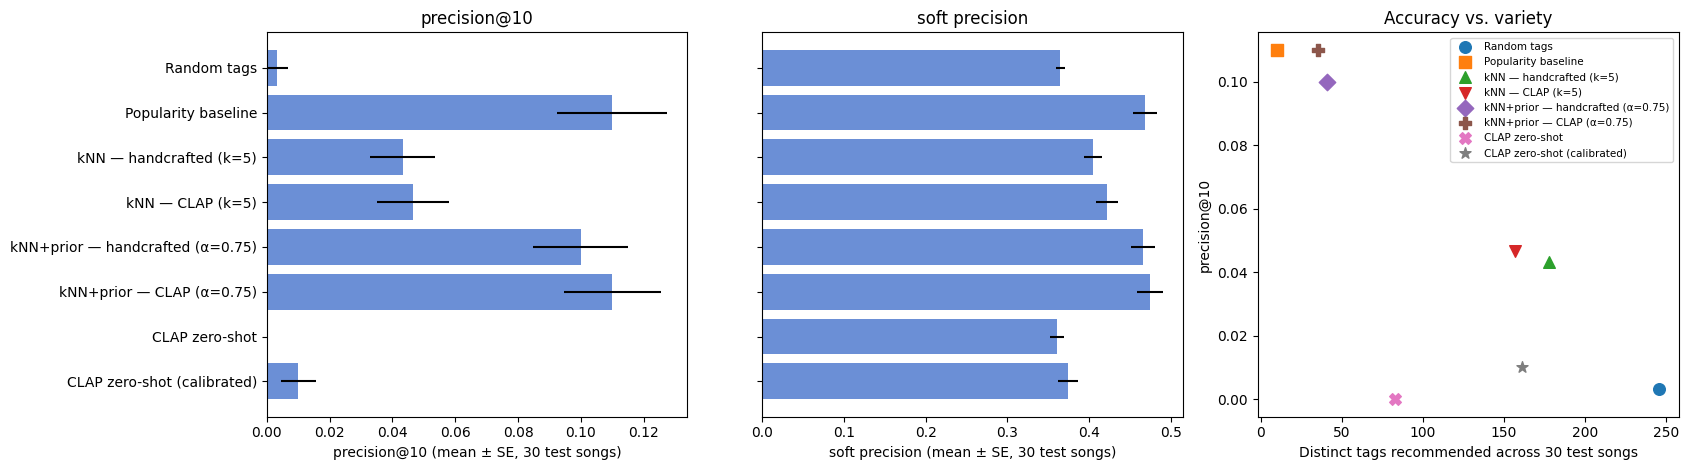

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, metric in zip(axes[:2], ["precision@10", "soft precision"]):
    m, s = res_B[(metric, "mean")], res_B[(metric, "sem")]
    ax.barh(m.index, m.values, xerr=s.values, color="#6b8fd6")
    ax.invert_yaxis(); ax.set_xlabel(f"{metric} (mean ± SE, 30 test songs)"); ax.set_title(metric)
axes[1].set_yticklabels([])

# Accuracy vs. variety: the baseline is accurate but gives every song the same tags
ax = axes[2]
x, y = res_B[("tag variety", "distinct")], res_B[("precision@10", "mean")]
markers = ["o", "s", "^", "v", "D", "P", "X", "*"]
for (name, mk) in zip(res_B.index, markers):
    ax.scatter(x[name], y[name], s=70, marker=mk, label=name)
ax.legend(fontsize=7.5, loc="upper right")
ax.set_xlabel("Distinct tags recommended across 30 test songs"); ax.set_ylabel("precision@10")
ax.set_title("Accuracy vs. variety")
plt.tight_layout(); plt.savefig(FIG / "tag_recommendation_comparison.png", dpi=150); plt.show()

### Results

* **CLAP zero-shot completely fails**: 0 exact hits, and its soft precision (0.361) is even a tiny bit *below random tags*
  (0.365). Its picks ("rally cars", "gays and girls", "testosterone") show it gravitates to vivid, unusual phrases that score high
  for almost every song. Calibrating (z-scoring each tag's similarity across training songs) barely helps (0.010).
  **A general-purpose model does not speak my personal tag language.**
* **Plain kNN is worse than the baseline** (0.047 vs. 0.110), because it copies neighbours' one-off tags.
* **kNN + prior with CLAP ties the popularity baseline** on exact matches (both 0.110) and has the highest soft precision
  (0.475 vs. 0.468). Honestly though, those gaps are smaller than the standard errors, so **I can't claim it beats the
  baseline** on accuracy. The ~30% gain from the α tuning didn't clearly show up on 30 test songs.
* **But look at variety:** the baseline gives *every song the same 10 tags* (10 distinct tags total), while kNN + prior
  CLAP gives 35 different tags at the same precision. For 777 Radio that matters a lot: if every song had identical tags, every
  image would match every song.

### Error analysis (Part B)

In [31]:
# 1. Side-by-side examples
best_name = f"kNN+prior — CLAP (α={best_alpha['CLAP']})"
show = ["Popularity baseline", "kNN — CLAP (k=5)", best_name, "CLAP zero-shot"]
for i in test_idx[:3]:
    print(f"\n=== {data.title[i]} — {data.artist[i]}")
    print(f"{'MY TAGS':34s}", ", ".join(data.tags[i]))
    for name in show:
        hits = set(preds[(name, i)]) & set(data.tags[i])
        print(f"{name:34s}", ", ".join(preds[(name, i)]), f"   [hits: {', '.join(hits) or '—'}]")


=== For You — TV Girl
MY TAGS                            cute, detached, forests, hearts, loving, mystery, pink, raindrops, small, sweet, unknown
Popularity baseline                street, cool, night, pink, party, confident, nature, love, cinematic, sad    [hits: pink]
kNN — CLAP (k=5)                   memories, flowers, lonely, meaningful, nature, places, reflective, affection, morning, nights    [hits: —]
kNN+prior — CLAP (α=0.75)          street, night, cool, romantic, pink, blue, nature, flowers, friends, cinematic    [hits: pink]
CLAP zero-shot                     greatness, classy life, rally cars, power, bold, gays and girls, macho, hot people, gay vibes, korean    [hits: —]

=== I'm not in love — 10cc
MY TAGS                            breath, calm, cool, dark, grey, heartbreak, love, nature dark green, nonchalant, sad, wind
Popularity baseline                street, cool, night, pink, party, confident, nature, love, cinematic, sad    [hits: love, cool, sad]
kNN — CLAP (k=5)

In [32]:
# 2. Per song: does the best model beat, tie or lose to the popularity baseline?
per_song = rec.pivot(index="song", columns="Method", values="precision@10")
diff = per_song[best_name] - per_song["Popularity baseline"]
print(f"{best_name} vs. popularity baseline on 30 test songs: "
      f"better {(diff > 0).sum()}, tie {(diff == 0).sum()}, worse {(diff < 0).sum()}")

# 3. Which tags are actually recovered? (are hits only my most common words?)
for name in ["Popularity baseline", best_name, "kNN — CLAP (k=5)"]:
    hit_tags = Counter(t for i in test_idx for t in set(preds[(name, i)]) & set(data.tags[i]))
    print(f"\n{name}: {sum(hit_tags.values())} correct tags in total")
    print("   ", ", ".join(f"{t} ×{n}" for t, n in hit_tags.most_common(12)))

# 4. Songs with no correct tag from the best model
zero = [i for i in test_idx if not set(preds[(best_name, i)]) & set(data.tags[i])]
print(f"\nTest songs with zero correct tags ({best_name}): {len(zero)} / {len(test_idx)}")
for i in zero[:6]:
    print(f"  - {data.title[i]} — my tags: {', '.join(data.tags[i][:8])}")

kNN+prior — CLAP (α=0.75) vs. popularity baseline on 30 test songs: better 6, tie 18, worse 6

Popularity baseline: 33 correct tags in total
    street ×6, cool ×5, sad ×5, love ×4, cinematic ×4, nature ×4, confident ×2, pink ×1, night ×1, party ×1

kNN+prior — CLAP (α=0.75): 33 correct tags in total
    street ×6, cool ×5, nature ×4, love ×3, sad ×3, romantic ×2, pink ×1, moving ×1, aesthetic ×1, cinematic ×1, night ×1, cars ×1

kNN — CLAP (k=5): 14 correct tags in total
    street ×3, love ×2, cool ×2, moving ×1, jazzy ×1, chains ×1, sad ×1, aesthetic ×1, night ×1, friends ×1

Test songs with zero correct tags (kNN+prior — CLAP (α=0.75)): 8 / 30
  - Scooby's In The Back — my tags: adventurous, evening, flowy, green, moving, no mood, rock
  - Midnight City — my tags: atmospheric, dreamy, nostalgic, saxophone, synth, urban nights
  - Silhouettes — my tags: cinematic, cocktail dresses, cooking, fine dining, fine evenings, high quality, jazzy, pasta
  - Runaway — my tags: cinematic, dram

### Try it: tagging unseen test songs

Here is the model used the way 777 Radio would use it: give it a song's audio embedding and it returns 10 suggested tags plus the
3 training songs it thinks sound most similar (which makes its "reasoning" visible). These are test songs 4–8, so they're
different from the examples above.

In [33]:
def suggest_tags(emb, k=15, alpha=best_alpha["CLAP"]):
    """Suggest K tags for a song from its CLAP embedding, using only the 115 training songs."""
    e = emb / np.linalg.norm(emb)
    sims = A[train_idx] @ e
    nn = np.argsort(-sims)[:k]
    w = np.maximum(sims[nn], 0) + 1e-9
    vote = (w[:, None] * Y[train_idx[nn]]).sum(0) / w.sum()
    prior = Y[train_idx].mean(0); prior = prior / prior.max()
    score = alpha * vote + (1 - alpha) * prior
    return [vocab[j] for j in np.argsort(-score)[:K]], [data.title[train_idx[j]] for j in nn[:3]]

for i in test_idx[3:8]:
    tags, similar = suggest_tags(data.loc[i, CLAP_COLS].to_numpy(dtype=float))
    hits = set(tags) & set(data.tags[i])
    print(f"\n♪ {data.title[i]} — {data.artist[i]}")
    print("  Suggested:  ", ", ".join(tags))
    print("  Sounds like:", ", ".join(similar))
    print("  My tags:    ", ", ".join(data.tags[i]))
    print("  Matches:    ", ", ".join(hits) or "—")


♪ Get Down On It — Kool & The Gang
  Suggested:   street, cool, moving, nature, night, cinematic, romantic, pink, confident, love
  Sounds like: 4 Minutes, Baby I'm Yours, More More More
  My tags:     cool, dancing, disco, free, funky, funny, gold, goofy, happy, life is good, old cities, ready for partying, vintage, weekend
  Matches:     cool

♪ DTMF — Bad Bunny
  Suggested:   street, night, cool, party, pink, confident, sad, dance, red, cars
  Sounds like: Good Kisser, The Lovecats, Cry Me A River
  My tags:     family, friends, latino, love, melancholic, memories, missing, sad, travel
  Matches:     sad

♪ Scooby's In The Back — HalfNoise
  Suggested:   street, cool, nature, pink, confident, morning, night, sun, sky, romantic
  Sounds like: She Needs Him, Class Historian, Rx Queen
  My tags:     adventurous, evening, flowy, green, moving, no mood, rock
  Matches:     —

♪ Midnight City — M83
  Suggested:   street, nature, pink, night, cool, aesthetic, confident, morning, cinematic

**Where it fails.** kNN + prior beats the baseline on 6 test songs, ties on 18 and loses on 6, so it's a wash. Both methods
recover 33 correct tags in total, and almost all of them are my common words (*street, cool, nature, love, sad*). The 8 songs
with **zero** correct tags (*Silhouettes*: "fine dining, pasta, cocktail dresses"; *La Fessée*: "croissants, influencer vibe";
*Runaway*: "orchestral, piano, epic") are exactly the ones I tagged with specific scenes or instruments that I barely used
anywhere else. The model never had a chance to learn those words.

# Summary of results

The cell below collects the key numbers from both parts into one place (all computed above, nothing typed by hand).

**Unsuccessful or weaker experiments kept on purpose** (they are part of the evidence):
* Number-based audio matching (abandoned because filename IDs drift from CSV IDs).
* CLAP zero-shot tagging, raw and calibrated: a generic audio–text model does not share my personal tag vocabulary.
* Plain kNN (k = 5): copies neighbors' one-off tags, which rarely transfer.

In [34]:
print("PART A — best model per label (selected by CV F1 on training songs)")
display(best_A[["features", "model", "CV F1 mean", "test F1"]].round(3))
print("Baselines, macro CV F1:")
display(summary_A.xs("Majority baseline", level="model")[["CV F1 (macro)"]]
        .join(summary_A.xs("Stratified baseline", level="model")[["CV F1 (macro)"]], lsuffix=" majority", rsuffix=" stratified"))

print("\nPART B — tag recommendation on 30 test songs")
means = res_B.loc[:, [(m, "mean") for m in ["precision@10", "recall@10", "soft precision"]]].droplevel(1, axis=1)
display(means.assign(**{"distinct tags": res_B[("tag variety", "distinct")]}).round(3))
print(f"Ceiling (max recall@10): {np.mean(ceiling):.3f}")

PART A — best model per label (selected by CV F1 on training songs)


,features,model,CV F1 mean,test F1
label,,,,
energetic,CLAP (512-d),Logistic regression,0.435,0.250
melancholic,Handcrafted (33-d),Decision tree,0.349,0.261
romantic,CLAP (512-d),SVM (RBF),0.427,0.667


Baselines, macro CV F1:


,CV F1 (macro) majority,CV F1 (macro) stratified
features,,
Handcrafted (33-d),0.0,0.153
CLAP (512-d),0.0,0.153



PART B — tag recommendation on 30 test songs


,precision@10,recall@10,soft precision,distinct tags
Method,,,,
Random tags,0.003,0.004,0.365,246
Popularity baseline,0.110,0.110,0.468,10
kNN — handcrafted (k=5),0.043,0.039,0.405,178
kNN — CLAP (k=5),0.047,0.041,0.423,157
kNN+prior — handcrafted (α=0.75),0.100,0.097,0.467,41
kNN+prior — CLAP (α=0.75),0.110,0.108,0.475,35
CLAP zero-shot,0.000,0.000,0.361,83
CLAP zero-shot (calibrated),0.010,0.010,0.375,161


Ceiling (max recall@10): 0.604


# Discussion, limitations and conclusion

**What worked.** The results suggest that audio contains useful information for predicting how I tag music, especially for broad aesthetic categories. In Part A, every model roughly doubled the F1 score of random guessing, and the pretrained CLAP embeddings gave logistic regression and the SVM a consistent improvement over my handcrafted features. This makes sense because my 33 handcrafted features summarize properties like loudness, rhythm, and sound texture, while CLAP has learned broader audio patterns from a large collection of audio-text examples. In Part B, combining information about similar-sounding songs with my overall tagging habits performed best during training-based model selection. However, the final test performance was similar to the popularity baseline, so I cannot claim that the more complicated approach clearly outperformed it.

**What didn't, and why.** One of the biggest limitations appears to be my data: I only have 145 songs, and many of my tags are rare or describe visual associations that may not be audible. In my current evaluation setup, where predictions are restricted to tags seen during training and each song receives at most ten suggestions, the maximum achievable average Recall@10 is about 60%. This is a limitation of my candidate vocabulary and evaluation setup, not a fundamental limit on what a better system could learn. CLAP zero-shot performing poorly was one of the most interesting findings for me. My tags are almost like a personal language, including phrases such as "rich kids vibe" and "older brother core." A model trained on more general audio descriptions may not understand those associations without examples from my own collection. Part A also revealed that some apparent prediction errors came from my keyword-based labeling rules, such as treating *dancing* differently from *dance*. This means some of the problem comes from imperfect labels rather than the models alone.

**What the ablation study taught me.** I initially expected that giving a model more audio features would improve its predictions. Instead, logistic regression achieved a higher average cross-validation F1 using just seven basic acoustic features (0.297) than with all 33 handcrafted features (0.224). Removing tempo-related features from the full set gave a smaller improvement to 0.241. This showed me why it is important to test which variables actually help instead of assuming that more information is always better. The additional features may introduce noise or redundant information, especially with a small training dataset. However, these results do not prove that any individual feature is universally useless.

**Limitations.** My test set is small, with only 3–8 positive examples per label in Part A, so a few predictions can change the F1 scores substantially. Many differences between models are also within the uncertainty shown by the error bars. The broad aesthetic labels come from my own keyword rules, which are imperfect. Soft precision is a similarity-based proxy that I have not yet validated against my own judgments of recommendation quality. Also, all the original tags were written by one person (me) at one point in time, so these results measure how predictable my personal taste is, not how people generally describe music. I only used one held-out train/test split, although cross-validation within the training set made the model comparisons more robust.

**Can this replace manual tagging in 777 Radio? Not yet.** On average, approximately one of the ten suggested tags matches a tag I originally wrote, while the broad aesthetic classifiers achieve F1 scores around 0.3–0.45. That is not reliable enough to replace my own tagging decisions. However, the system could already work as a tagging assistant by suggesting common tags such as *street*, *cool*, *night*, *sad*, and *love*, along with tags from similar songs, for me to accept or remove. This would give me a starting point instead of having to tag every song from scratch.

For Pipeline 2, I would collect more songs, improve the keyword-labeling rules using word-stem matching, and experiment with analyzing song lyrics alongside the audio. Lyrics might help capture emotional themes, relationships, and storytelling that are difficult to identify from sound alone. I would compare audio-only, lyrics-only, and combined audio-and-lyrics models to see whether adding textual information actually improves tag prediction. Ultimately, I want to test whether automatically tagged songs still produce good image-to-song recommendations, since that is the main purpose of 777 Radio.

## References

**Machine learning and audio processing**

- McFee, B. et al. *librosa: Audio and Music Signal Analysis in Python.* Documentation: https://librosa.org/doc/
- Wu, Y. et al. (2023). *Large-scale Contrastive Language-Audio Pretraining with Feature Fusion and Keyword-to-Caption Augmentation (CLAP).* Pretrained model: https://huggingface.co/laion/clap-htsat-unfused
- Reimers, N., & Gurevych, I. (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks.* https://www.sbert.net/
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python.* https://scikit-learn.org/stable/
- NumPy documentation: https://numpy.org/doc/
- pandas documentation: https://pandas.pydata.org/docs/
- Matplotlib documentation: https://matplotlib.org/stable/

**Course materials**

- CS156 course lectures and pre-class work (PCWs), Fall 2026. Used as background for supervised learning, logistic regression, decision trees, model evaluation, and cross-validation.

**Project and data sources**

- *777 Radio.* My personal image-to-song recommendation app, which motivated this project and the idea of predicting my aesthetic music tags. https://777radio.vercel.app/
- My personal music collection and `music-dataset.csv`, containing 162 songs with metadata and manually curated aesthetic tags. I successfully matched 145 songs to audio files for this experiment.
- Spotify: https://open.spotify.com/playlist/0sCzSiXHyGUii3EpeJOzFd?si=4xqIaJyAS9KmptNKjbH-Ig — used for song metadata and identifiers, where applicable.
- Spotidown.co. *Spotify Downloader.* https://spotidown.co/ — Third-party service I used to obtain MP3 copies of songs from my personal Spotify playlist for audio feature extraction and analysis. The audio files were used for this project and are not included in the public GitHub repository.

## AI use statement

I used ChatGPT throughout this project as a supporting tool for brainstorming, troubleshooting, understanding unfamiliar concepts, and improving the clarity and organization of my notebook.

The original 777 Radio app, music collection, and aesthetic tags are my own. I ran the experiments in Google Colab, reviewed the results, compared different approaches, and made the final decisions myself. All numerical results come from executed experiments rather than AI-generated estimates.

## Ethical considerations

**Copyright and data use.** My dataset comes from my personal music collection and Spotify playlist. I used Spotidown.co, a third-party service, to obtain MP3 files for audio analysis. Since these songs are copyrighted, I need to distinguish using audio for an experiment from having permission to redistribute it. I will not upload the MP3 files to my public GitHub repository. Instead, I will share the code, feature data where appropriate, and instructions explaining how the pipeline works. Using a third-party downloader also raises questions about platform terms and music licensing, so I would need to review those restrictions before distributing or deploying this system.

**Privacy and personal data.** The tags reflect my own associations with music, including emotions, memories, and visual aesthetics. Although this is my personal collection, I should still be careful about what I make public. I can share non-sensitive metadata and the methods used to analyze it without publishing private listening information or personal notes that I do not want others to see.

**Bias and subjectivity.** My models learn from tags assigned by one person: me. This means they are learning my interpretation of music, not an objective definition of what sounds romantic, melancholic, or energetic. Some of my tags describe images or social associations that cannot necessarily be inferred from audio. I should avoid presenting those predictions as universal truths or using them to make assumptions about listeners or artists.

**Responsible use of pretrained models.** CLAP was trained on external audio-text data that I did not collect or fully audit. Its learned associations may not match my personal tagging vocabulary and may reflect biases in its training data. I therefore treat its predictions as suggestions rather than facts. Before using automatic tagging in 777 Radio, I would want to evaluate the recommendations with actual users and keep the option to review, correct, or reject them.